In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [ ]:
!pip install -q kaggle

In [ ]:
import os
from google.colab import userdata

# Retrieve token from Colab Secrets
token = userdata.get("KAGGLE_API_TOKEN")

# Configure Kaggle authentication
os.environ["KAGGLE_API_TOKEN"] = token

print("Kaggle token configured successfully!")

Kaggle token configured successfully!


In [ ]:
!kaggle datasets list -s gtsrb

ref                                                             title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------  -------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
meowmeowmeowmeowmeow/gtsrb-german-traffic-sign                  GTSRB - German Traffic Sign Recognition Benchmark    641568792  2018-11-25 18:12:34.427000         192491       1365  0.8235294        
harbhajansingh21/german-traffic-sign-dataset                    German Traffic Sign Dataset                          123621493  2023-07-11 04:21:24.180000           4086         43  1                
daniildeltsov/traffic-signs-gtsrb-plus-162-custom-classes       Traffic Signs (GTSRB plus 162 custom classes)      16274543717  2022-04-15 14:59:47.803000           1376         46  0.88235295       


In [ ]:
!mkdir -p /content/data

!kaggle datasets download \
    -d meowmeowmeowmeowmeow/gtsrb-german-traffic-sign \
    -p /content/data

Dataset URL: https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
License(s): CC0-1.0
100% 612M/612M [00:07<00:00, 81.3MB/s]



In [ ]:
import zipfile
import glob
import os

zip_path = glob.glob("/content/data/*.zip")[0]

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/data/extracted")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
for root, dirs, files in os.walk("/content/data/extracted"):
    level = root.replace("/content/data/extracted", "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

extracted/
  Test/
  Meta/
  meta/
  Train/
    25/
    41/
    24/
    14/
    17/
    15/
    31/
    5/
    13/
    9/
    38/
    39/
    42/
    8/
    23/
    32/
    35/
    22/
    30/
    29/
    36/
    7/
    27/
    1/
    18/
    10/
    28/
    40/
    19/
    6/
    21/
    26/
    0/
    16/
    2/
    33/
    3/
    37/
    20/
    11/
    34/
    12/
    4/
  test/
  train/
    25/
    41/
    24/
    14/
    17/
    15/
    31/
    5/
    13/
    9/
    38/
    39/
    42/
    8/
    23/
    32/
    35/
    22/
    30/
    29/
    36/
    7/
    27/
    1/
    18/
    10/
    28/
    40/
    19/
    6/
    21/
    26/
    0/
    16/
    2/
    33/
    3/
    37/
    20/
    11/
    34/
    12/
    4/


In [ ]:
import os
import random
import matplotlib.pyplot as plt

from PIL import Image

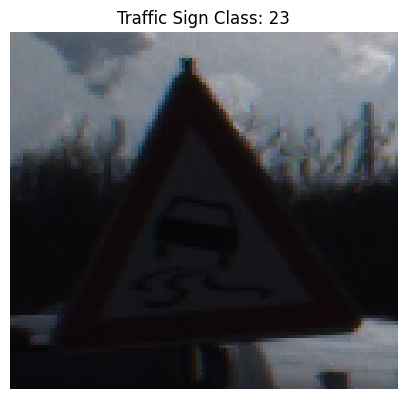

Image size: (115, 106)
Image mode: RGB


In [ ]:
train_path = "/content/data/extracted/Train"

# Select a random class
classes = os.listdir(train_path)
selected_class = random.choice(classes)

# Select a random image
class_path = os.path.join(train_path, selected_class)
image_name = random.choice(os.listdir(class_path))

image_path = os.path.join(class_path, image_name)

# Load and display image
image = Image.open(image_path)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(f"Traffic Sign Class: {selected_class}")
plt.axis("off")
plt.show()

print("Image size:", image.size)
print("Image mode:", image.mode)

In [ ]:
class_counts = {}

for class_id in sorted(os.listdir(train_path), key=int):
    class_path = os.path.join(train_path, class_id)

    if os.path.isdir(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]

        class_counts[int(class_id)] = len(images)

print("Number of classes:", len(class_counts))
print("Total training images:", sum(class_counts.values()))

for class_id, count in class_counts.items():
    print(f"Class {class_id}: {count} images")

Number of classes: 43
Total training images: 39209
Class 0: 210 images
Class 1: 2220 images
Class 2: 2250 images
Class 3: 1410 images
Class 4: 1980 images
Class 5: 1860 images
Class 6: 420 images
Class 7: 1440 images
Class 8: 1410 images
Class 9: 1470 images
Class 10: 2010 images
Class 11: 1320 images
Class 12: 2100 images
Class 13: 2160 images
Class 14: 780 images
Class 15: 630 images
Class 16: 420 images
Class 17: 1110 images
Class 18: 1200 images
Class 19: 210 images
Class 20: 360 images
Class 21: 330 images
Class 22: 390 images
Class 23: 510 images
Class 24: 270 images
Class 25: 1500 images
Class 26: 600 images
Class 27: 240 images
Class 28: 540 images
Class 29: 270 images
Class 30: 450 images
Class 31: 780 images
Class 32: 240 images
Class 33: 689 images
Class 34: 420 images
Class 35: 1200 images
Class 36: 390 images
Class 37: 210 images
Class 38: 2070 images
Class 39: 300 images
Class 40: 360 images
Class 41: 240 images
Class 42: 240 images


In [ ]:
class_names = {
    0: "Speed limit (20km/h)",
    1: "Speed limit (30km/h)",
    2: "Speed limit (50km/h)",
    3: "Speed limit (60km/h)",
    4: "Speed limit (70km/h)",
    5: "Speed limit (80km/h)",
    6: "End of speed limit (80km/h)",
    7: "Speed limit (100km/h)",
    8: "Speed limit (120km/h)",
    9: "No passing",
    10: "No passing for vehicles over 3.5 tons",
    11: "Right-of-way at next intersection",
    12: "Priority road",
    13: "Yield",
    14: "Stop",
    15: "No vehicles",
    16: "Vehicles over 3.5 tons prohibited",
    17: "No entry",
    18: "General caution",
    19: "Dangerous curve to the left",
    20: "Dangerous curve to the right",
    21: "Double curve",
    22: "Bumpy road",
    23: "Slippery road",
    24: "Road narrows on the right",
    25: "Road work",
    26: "Traffic signals",
    27: "Pedestrians",
    28: "Children crossing",
    29: "Bicycles crossing",
    30: "Beware of ice/snow",
    31: "Wild animals crossing",
    32: "End of all speed and passing limits",
    33: "Turn right ahead",
    34: "Turn left ahead",
    35: "Ahead only",
    36: "Go straight or right",
    37: "Go straight or left",
    38: "Keep right",
    39: "Keep left",
    40: "Roundabout mandatory",
    41: "End of no passing",
    42: "End of no passing by vehicles over 3.5 tons"
}

print("Total classes:", len(class_names))

for class_id, name in class_names.items():
    print(f"{class_id}: {name}")

Total classes: 43
0: Speed limit (20km/h)
1: Speed limit (30km/h)
2: Speed limit (50km/h)
3: Speed limit (60km/h)
4: Speed limit (70km/h)
5: Speed limit (80km/h)
6: End of speed limit (80km/h)
7: Speed limit (100km/h)
8: Speed limit (120km/h)
9: No passing
10: No passing for vehicles over 3.5 tons
11: Right-of-way at next intersection
12: Priority road
13: Yield
14: Stop
15: No vehicles
16: Vehicles over 3.5 tons prohibited
17: No entry
18: General caution
19: Dangerous curve to the left
20: Dangerous curve to the right
21: Double curve
22: Bumpy road
23: Slippery road
24: Road narrows on the right
25: Road work
26: Traffic signals
27: Pedestrians
28: Children crossing
29: Bicycles crossing
30: Beware of ice/snow
31: Wild animals crossing
32: End of all speed and passing limits
33: Turn right ahead
34: Turn left ahead
35: Ahead only
36: Go straight or right
37: Go straight or left
38: Keep right
39: Keep left
40: Roundabout mandatory
41: End of no passing
42: End of no passing by vehic

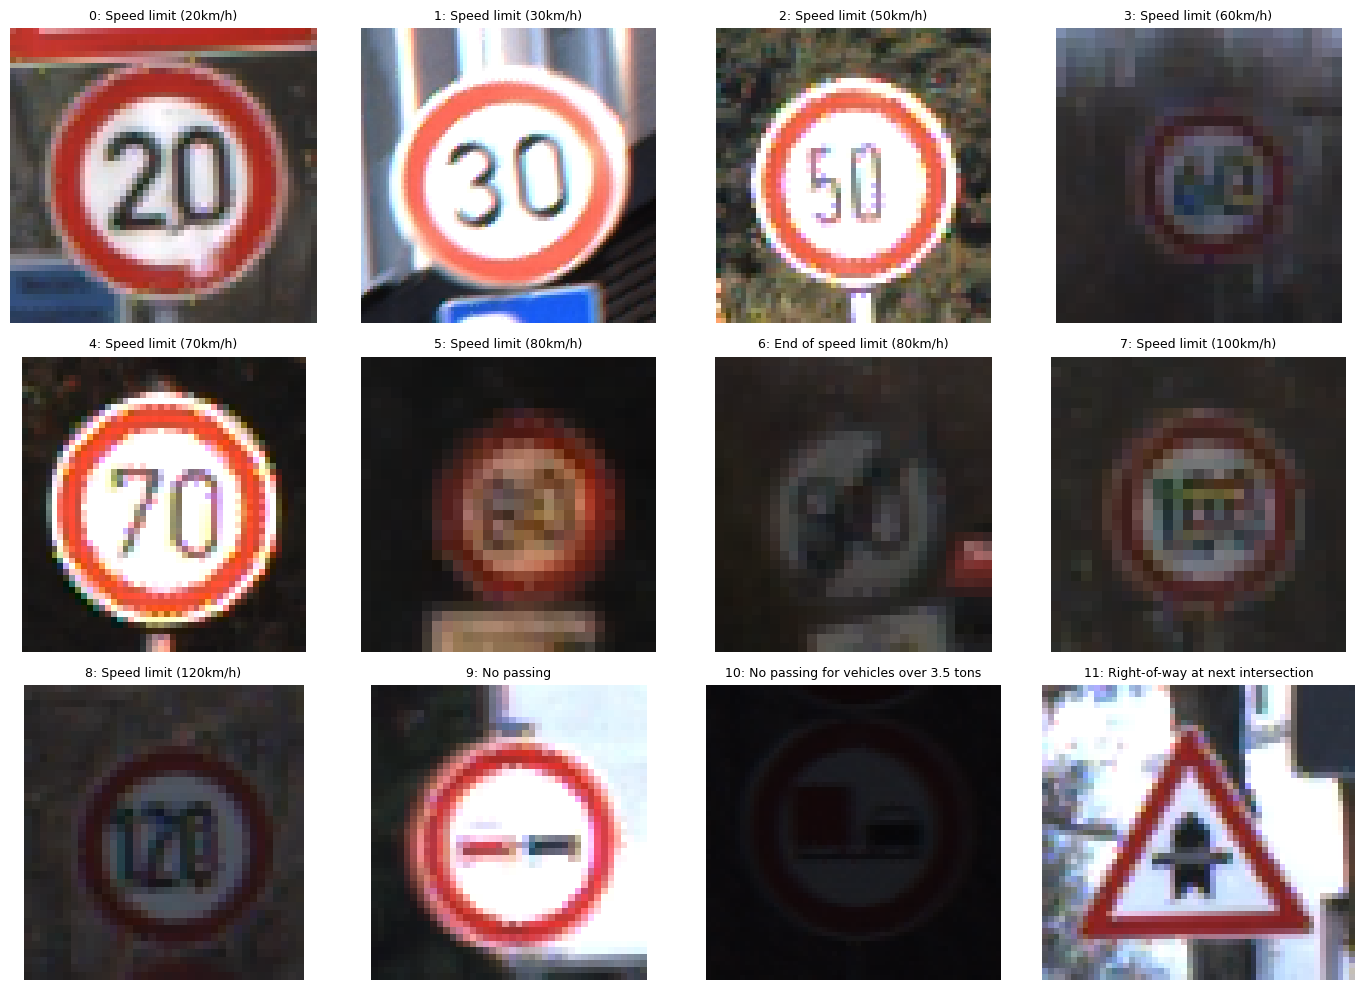

In [ ]:
import matplotlib.pyplot as plt
import random
import os
from PIL import Image

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for class_id, ax in enumerate(axes.flat):
    class_path = os.path.join(train_path, str(class_id))

    image_name = random.choice(os.listdir(class_path))
    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(f"{class_id}: {class_names[class_id]}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torchvision
from torchvision import transforms
from torchvision.datasets import ImageFolder

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130


In [ ]:
# ImageNet normalization values
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Image preprocessing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Image transformations defined successfully!")

Image transformations defined successfully!


In [ ]:
train_path = "/content/data/extracted/Train"

dataset = ImageFolder(
    root=train_path,
    transform=transform
)

print("Total images:", len(dataset))
print("Total classes:", len(dataset.classes))
print("ImageFolder class order:", dataset.classes)

Total images: 39209
Total classes: 43
ImageFolder class order: ['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '4', '40', '41', '42', '5', '6', '7', '8', '9']


In [ ]:
image, label = dataset[0]

print("Image tensor shape:", image.shape)
print("Label:", label)
print("Class folder:", dataset.classes[label])
print("Traffic sign:", class_names[int(dataset.classes[label])])

Image tensor shape: torch.Size([3, 224, 224])
Label: 0
Class folder: 0
Traffic sign: Speed limit (20km/h)


In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset, DataLoader
import numpy as np

In [ ]:
# Get labels of all images
labels = np.array(dataset.targets)

# Generate indices
indices = np.arange(len(dataset))

# Stratified 80:20 split
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))

Training samples: 31367
Validation samples: 7842


In [ ]:
train_dataset = Subset(dataset, train_indices)
val_dataset = Subset(dataset, val_indices)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Training dataset: 31367
Validation dataset: 7842


In [ ]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 491
Validation batches: 123


In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])

Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
First 10 labels: tensor([ 5, 12,  5,  6,  1, 20, 27, 18, 34, 10])


In [ ]:
# Map model output indices to original traffic sign class IDs
idx_to_class_id = [
    int(folder_name) for folder_name in dataset.classes
]

print("Model output index 2 represents class:",
      idx_to_class_id[2])

print("Traffic sign name:",
      class_names[idx_to_class_id[2]])

Model output index 2 represents class: 10
Traffic sign name: No passing for vehicles over 3.5 tons


In [ ]:
import torch.nn as nn
from torchvision import models

# Select GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load pretrained ResNet18
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

# Replace final classification layer
num_features = model.fc.in_features

model.fc = nn.Linear(num_features, 43)

# Move model to GPU
model = model.to(device)

print("Model loaded successfully!")
print("Device:", device)
print("Output classes:", model.fc.out_features)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s]


Model loaded successfully!
Device: cuda
Output classes: 43


In [ ]:
# Get one batch
images, labels = next(iter(train_loader))

# Move images to GPU
images = images.to(device)

# Test model
model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 224, 224])
Output shape: torch.Size([64, 43])


In [ ]:
criterion = nn.CrossEntropyLoss()

print("Loss function:", criterion)

Loss function: CrossEntropyLoss()


In [ ]:
optimizer = torch.optim.Adam([
    {
        "params": model.fc.parameters(),
        "lr": 0.001
    },
    {
        "params": [
            param for name, param in model.named_parameters()
            if not name.startswith("fc.")
        ],
        "lr": 0.0001
    }
])

print("Optimizer:", optimizer)

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0

Parameter Group 1
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [ ]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Learning rate scheduler configured!")

Learning rate scheduler configured!


In [ ]:
print("Device:", device)
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Scheduler:", scheduler.__class__.__name__)

print("\nLearning rates:")

for i, group in enumerate(optimizer.param_groups):
    print(f"Parameter group {i}: {group['lr']}")

Device: cuda
Loss function: CrossEntropyLoss()
Optimizer: Adam
Scheduler: ReduceLROnPlateau

Learning rates:
Parameter group 0: 0.001
Parameter group 1: 0.0001


In [ ]:
import time

num_epochs = 10

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = 0.0

for epoch in range(num_epochs):

    start_time = time.time()

    # -------------------------
    # Training
    # -------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = 100 * val_correct / val_total

    # Update learning rate
    scheduler.step(val_loss)

    # Save metrics
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc

        torch.save(model.state_dict(),
                   "/content/best_resnet18_gtsrb.pth")

    elapsed = time.time() - start_time

    print(f"Epoch [{epoch+1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_acc:.2f}%")
    print(f"Time: {elapsed/60:.2f} minutes")
    print("-" * 50)

print("Training completed!")
print(f"Best validation accuracy: {best_val_acc:.2f}%")

Epoch [1/10]
Train Loss: 0.2416 | Train Accuracy: 94.11%
Val Loss:   0.0134 | Val Accuracy:   99.71%
Time: 1.84 minutes
--------------------------------------------------
Epoch [2/10]
Train Loss: 0.0060 | Train Accuracy: 99.85%
Val Loss:   0.0047 | Val Accuracy:   99.87%
Time: 1.87 minutes
--------------------------------------------------
Epoch [3/10]
Train Loss: 0.0022 | Train Accuracy: 99.95%
Val Loss:   0.0079 | Val Accuracy:   99.80%
Time: 1.87 minutes
--------------------------------------------------
Epoch [4/10]
Train Loss: 0.0089 | Train Accuracy: 99.76%
Val Loss:   0.0374 | Val Accuracy:   99.16%
Time: 1.86 minutes
--------------------------------------------------
Epoch [5/10]
Train Loss: 0.0080 | Train Accuracy: 99.82%
Val Loss:   0.0021 | Val Accuracy:   99.94%
Time: 1.88 minutes
--------------------------------------------------
Epoch [6/10]
Train Loss: 0.0052 | Train Accuracy: 99.86%
Val Loss:   0.0027 | Val Accuracy:   99.91%
Time: 1.86 minutes
-------------------------

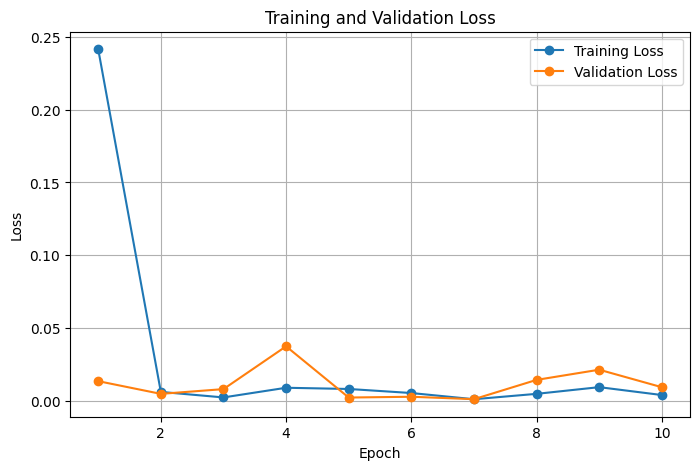

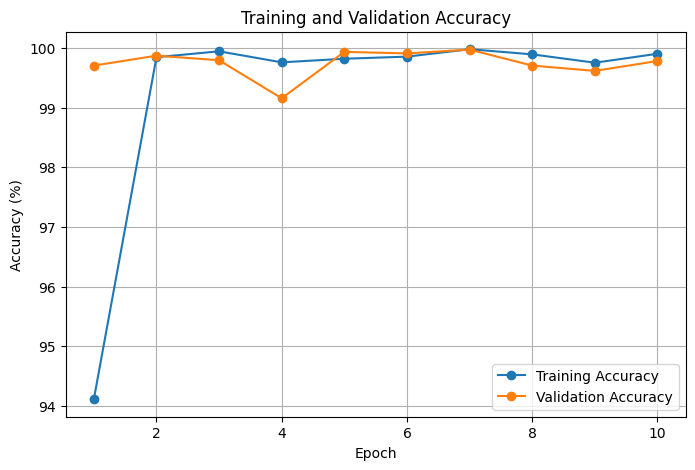

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_acc"], marker="o", label="Training Accuracy")
plt.plot(epochs, history["val_acc"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import os

base_path = "/content/data/extracted"

for folder in ["Test", "test"]:
    path = os.path.join(base_path, folder)

    print(f"\n--- {folder} folder ---")

    if os.path.exists(path):
        items = os.listdir(path)

        print("Total items:", len(items))
        print("First 15 items:", items[:15])

        for item in items[:5]:
            item_path = os.path.join(path, item)

            if os.path.isdir(item_path):
                print(f"{item}/ contains:", os.listdir(item_path)[:5])
    else:
        print("Folder not found!")

print("\n--- CSV files ---")

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))


--- Test folder ---
Total items: 12631
First 15 items: ['05178.png', '05991.png', '00802.png', '03799.png', '10554.png', '11145.png', '11427.png', '12444.png', '06759.png', '05393.png', '02909.png', '03545.png', '10464.png', '05158.png', '01698.png']

--- test folder ---
Total items: 12631
First 15 items: ['05178.png', '05991.png', '00802.png', '03799.png', '10554.png', '11145.png', '11427.png', '12444.png', '06759.png', '05393.png', '02909.png', '03545.png', '10464.png', '05158.png', '01698.png']

--- CSV files ---
/content/data/extracted/Train.csv
/content/data/extracted/Meta.csv
/content/data/extracted/Test.csv
/content/data/extracted/Test/GT-final_test.csv
/content/data/extracted/test/GT-final_test.csv


In [ ]:
import os

csv_paths = [
    "/content/data/extracted/Test/GT-final_test.csv",
    "/content/data/extracted/test/GT-final_test.csv",
    "/content/data/extracted/Test.csv",
    "/content/data/extracted/Train.csv"
]

for path in csv_paths:
    print("\nFile:", path)

    if os.path.exists(path):
        print("Size:", os.path.getsize(path), "bytes")

        with open(path, "rb") as f:
            print("First 300 bytes:", f.read(300))
    else:
        print("File does not exist")


File: /content/data/extracted/Test/GT-final_test.csv
Size: 0 bytes
First 300 bytes: b''

File: /content/data/extracted/test/GT-final_test.csv
Size: 0 bytes
First 300 bytes: b''

File: /content/data/extracted/Test.csv
Size: 427897 bytes
First 300 bytes: b'Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path\n53,54,6,5,48,49,16,Test/00000.png\n42,45,5,5,36,40,1,Test/00001.png\n48,52,6,6,43,47,38,Test/00002.png\n27,29,5,5,22,24,33,Test/00003.png\n60,57,5,5,55,52,11,Test/00004.png\n52,56,5,5,47,51,38,Test/00005.png\n147,130,12,12,135,119,18,Test/00006.png\n32,'

File: /content/data/extracted/Train.csv
Size: 1940896 bytes
First 300 bytes: b'Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path\n27,26,5,5,22,20,20,Train/20/00020_00000_00000.png\n28,27,5,6,23,22,20,Train/20/00020_00000_00001.png\n29,26,6,5,24,21,20,Train/20/00020_00000_00002.png\n28,27,5,6,23,22,20,Train/20/00020_00000_00003.png\n28,26,5,5,23,21,20,Train/20/00020_00000_00004.'


In [ ]:
test_csv_path = "/content/data/extracted/Test.csv"

test_df = pd.read_csv(test_csv_path)

print("Number of test images:", len(test_df))
print("Number of unique classes:", test_df["ClassId"].nunique())

print("\nCSV columns:")
print(test_df.columns.tolist())

print("\nFirst 5 records:")
display(test_df.head())

print("\nClass distribution:")
print(test_df["ClassId"].value_counts().sort_index())

Number of test images: 12630
Number of unique classes: 43

CSV columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

First 5 records:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png



Class distribution:
ClassId
0      60
1     720
2     750
3     450
4     660
5     630
6     150
7     450
8     450
9     480
10    660
11    420
12    690
13    720
14    270
15    210
16    150
17    360
18    390
19     60
20     90
21     90
22    120
23    150
24     90
25    480
26    180
27     60
28    150
29     90
30    150
31    270
32     60
33    210
34    120
35    390
36    120
37     60
38    690
39     90
40     90
41     60
42     90
Name: count, dtype: int64


In [ ]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import os

class GTSRBTestDataset(Dataset):

    def __init__(self, dataframe, root_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = os.path.join(self.root_dir, row["Path"])

        image = Image.open(image_path).convert("RGB")
        label = int(row["ClassId"])

        if self.transform:
            image = self.transform(image)

        return image, label


# Create test dataset
test_dataset = GTSRBTestDataset(
    dataframe=test_df,
    root_dir="/content/data/extracted",
    transform=transform
)

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Test dataset created successfully!")
print("Total test images:", len(test_dataset))
print("Total test batches:", len(test_loader))

# Check one batch
images, labels = next(iter(test_loader))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])

Test dataset created successfully!
Total test images: 12630
Total test batches: 198

Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
First 10 labels: tensor([16,  1, 38, 33, 11, 38, 18, 12, 25, 35])


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Load the best model
model.load_state_dict(
    torch.load(
        "/content/best_resnet18_gtsrb.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

all_predictions = []
all_labels = []

# Evaluate on test dataset
with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())


# Calculate evaluation metrics
accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

recall = recall_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

f1 = f1_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

print("OFFICIAL TEST RESULTS")
print("-" * 40)
print(f"Test Accuracy : {accuracy * 100:.2f}%")
print(f"Precision     : {precision * 100:.2f}%")
print(f"Recall        : {recall * 100:.2f}%")
print(f"F1 Score      : {f1 * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(43)),
        target_names=[class_names[i] for i in range(43)],
        zero_division=0
    )
)

OFFICIAL TEST RESULTS
----------------------------------------
Test Accuracy : 6.25%
Precision     : 4.72%
Recall        : 4.86%
F1 Score      : 4.74%

Classification Report:
                                             precision    recall  f1-score   support

                       Speed limit (20km/h)       1.00      1.00      1.00        60
                       Speed limit (30km/h)       1.00      1.00      1.00       720
                       Speed limit (50km/h)       0.00      0.00      0.00       750
                       Speed limit (60km/h)       0.00      0.00      0.00       450
                       Speed limit (70km/h)       0.00      0.00      0.00       660
                       Speed limit (80km/h)       0.00      0.00      0.00       630
                End of speed limit (80km/h)       0.00      0.00      0.00       150
                      Speed limit (100km/h)       0.00      0.00      0.00       450
                      Speed limit (120km/h)       0.00     

In [ ]:
# Convert model output indices to original GTSRB class IDs
corrected_predictions = [
    idx_to_class_id[pred]
    for pred in all_predictions
]

# Calculate corrected metrics
accuracy = accuracy_score(all_labels, corrected_predictions)

precision = precision_score(
    all_labels, corrected_predictions,
    average="macro", zero_division=0
)

recall = recall_score(
    all_labels, corrected_predictions,
    average="macro", zero_division=0
)

f1 = f1_score(
    all_labels, corrected_predictions,
    average="macro", zero_division=0
)

print("CORRECTED OFFICIAL TEST RESULTS")
print("-" * 40)
print(f"Test Accuracy : {accuracy * 100:.2f}%")
print(f"Precision     : {precision * 100:.2f}%")
print(f"Recall        : {recall * 100:.2f}%")
print(f"F1 Score      : {f1 * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        corrected_predictions,
        labels=list(range(43)),
        target_names=[class_names[i] for i in range(43)],
        zero_division=0
    )
)

CORRECTED OFFICIAL TEST RESULTS
----------------------------------------
Test Accuracy : 98.99%
Precision     : 99.19%
Recall        : 98.53%
F1 Score      : 98.82%

Classification Report:
                                             precision    recall  f1-score   support

                       Speed limit (20km/h)       1.00      1.00      1.00        60
                       Speed limit (30km/h)       1.00      1.00      1.00       720
                       Speed limit (50km/h)       1.00      1.00      1.00       750
                       Speed limit (60km/h)       1.00      0.97      0.99       450
                       Speed limit (70km/h)       1.00      1.00      1.00       660
                       Speed limit (80km/h)       0.95      1.00      0.97       630
                End of speed limit (80km/h)       1.00      1.00      1.00       150
                      Speed limit (100km/h)       0.98      1.00      0.99       450
                      Speed limit (120km/h)  

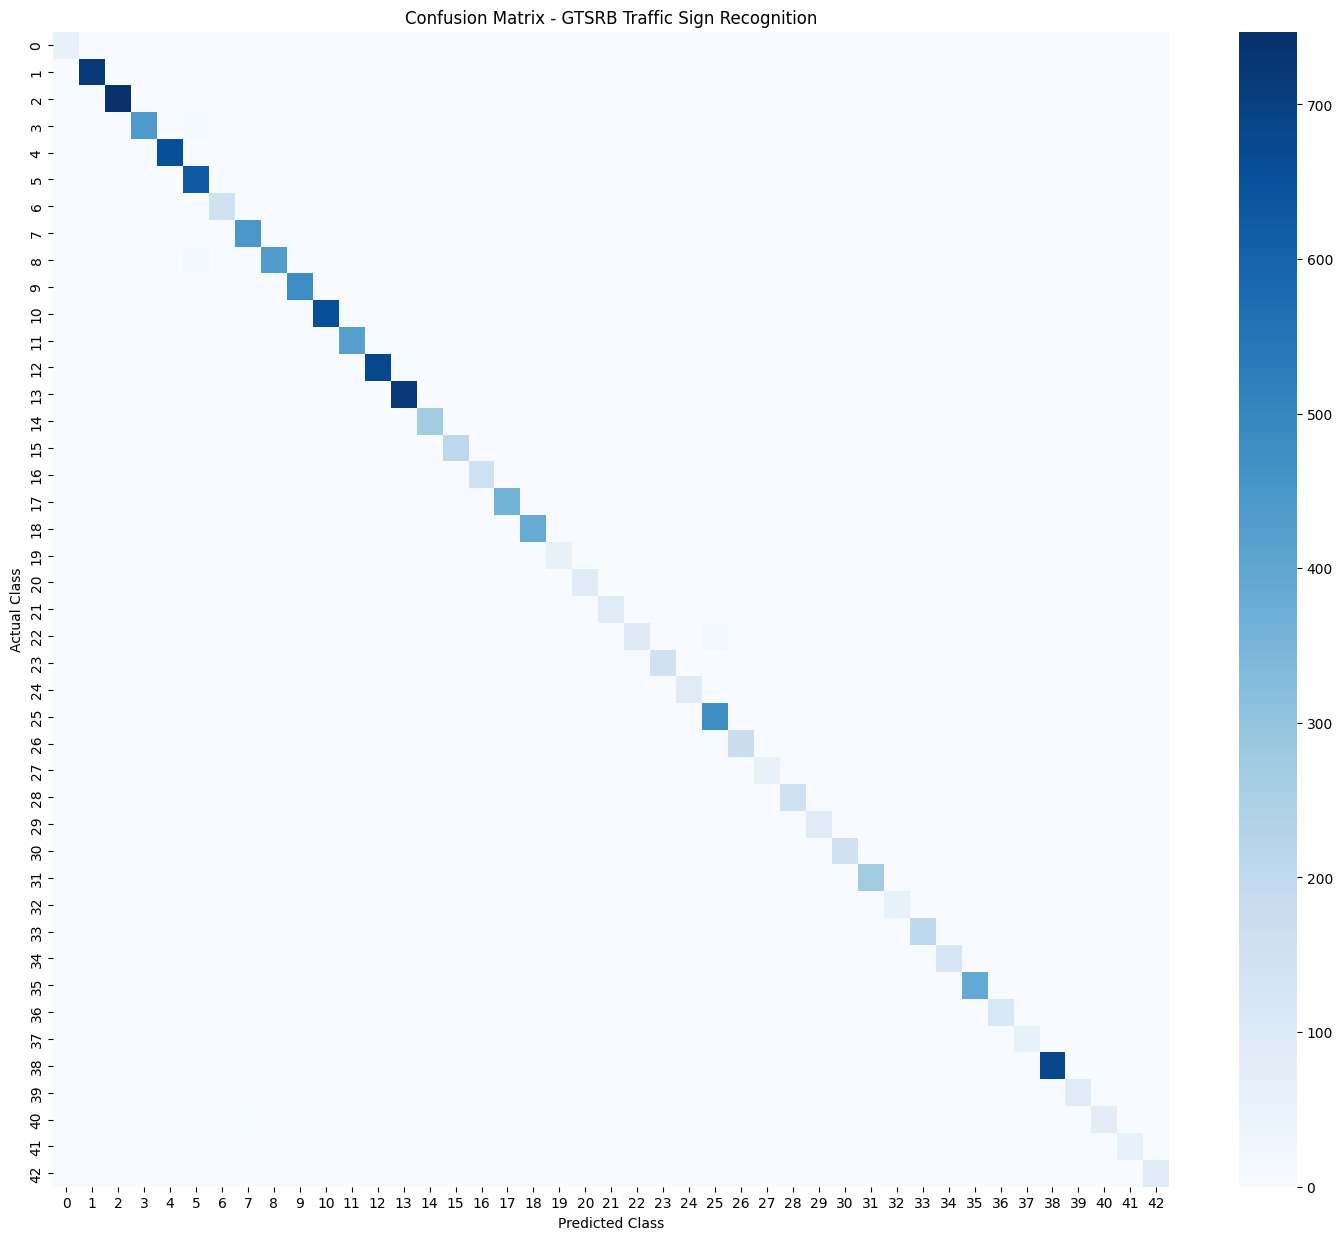

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    corrected_predictions,
    labels=list(range(43))
)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=list(range(43)),
    yticklabels=list(range(43))
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - GTSRB Traffic Sign Recognition")

plt.show()

Saving 00036_00000_00000.png to 00036_00000_00000.png


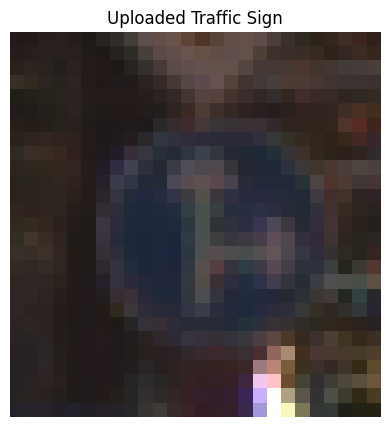

PREDICTION RESULT
-----------------------------------
Traffic Sign: Go straight or right
Confidence: 100.00%


In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import torch

# Upload traffic sign image
uploaded = files.upload()

# Get uploaded image
image_path = next(iter(uploaded))

# Open image
image = Image.open(image_path).convert("RGB")

# Preprocess image
input_tensor = transform(image).unsqueeze(0).to(device)

# Predict
model.eval()

with torch.no_grad():
    outputs = model(input_tensor)

    probabilities = torch.softmax(outputs, dim=1)

    predicted_index = outputs.argmax(dim=1).item()

    confidence = probabilities[0, predicted_index].item() * 100

# Convert model index to original class ID
predicted_class_id = idx_to_class_id[predicted_index]

# Get traffic sign name
predicted_name = class_names[predicted_class_id]

# Display results
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Traffic Sign")
plt.show()

print("PREDICTION RESULT")
print("-" * 35)
print("Traffic Sign:", predicted_name)
print(f"Confidence: {confidence:.2f}%")

In [ ]:
import os
import json
import torch
import zipfile

backup_dir = "/content/traffic_sign_backup"
os.makedirs(backup_dir, exist_ok=True)

# 1. Save model checkpoint
checkpoint = {
    "model_name": "ResNet18",
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "idx_to_class_id": idx_to_class_id,
    "num_classes": 43,
    "input_size": 224,
    "mean": [0.485, 0.456, 0.406],
    "std": [0.229, 0.224, 0.225],
    "test_accuracy": 98.99,
    "precision": 99.19,
    "recall": 98.53,
    "f1_score": 98.82
}

torch.save(
    checkpoint,
    os.path.join(backup_dir, "traffic_sign_model.pth")
)

# 2. Save class mapping separately
with open(os.path.join(backup_dir, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=4)

# 3. Save training history
with open(os.path.join(backup_dir, "training_history.json"), "w") as f:
    json.dump(history, f, indent=4)

# 4. Create ZIP backup
zip_path = "/content/traffic_sign_project_backup.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
    for filename in os.listdir(backup_dir):
        file_path = os.path.join(backup_dir, filename)
        zipf.write(file_path, arcname=filename)

print("Backup created successfully!")
print("Files:", os.listdir(backup_dir))
print("ZIP location:", zip_path)

Backup created successfully!
Files: ['class_names.json', 'training_history.json', 'traffic_sign_model.pth']
ZIP location: /content/traffic_sign_project_backup.zip


In [ ]:
from google.colab import files

files.download("/content/traffic_sign_project_backup.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>